# FL-SEC-001.4 — SMPC aggregation with authenticated shares (SPDZ-style)

*Epic EPIC-001 · story fl_sec_001 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Implement additive secret sharing with information-theoretic MACs, Beaver triples and MAC-checked opening; detect share tampering.

## 2. Scientific background
SPDZ-style protocols authenticate shares with a global MAC key [damgard2012]; Beaver triples enable multiplication [beaver1991]. The offline phase here is a trusted dealer (NOT a real preprocessing protocol).

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Is the aggregate exact?
- **RQ2.** Is share tampering detected?
- **RQ3.** How do costs scale with parties and clients?

## 4. Hypotheses
- **H1.** Aggregate error < 1e-5.
- **H2.** Any single-share modification triggers MAC failure.

## 5. Mathematical formulation
x = Σ_i x_i mod p, p=2^61−1; MAC m_j = α_j x; check Σ_i (m_j)_i − α_j x = 0 for each of K=2 keys; Beaver: z = c + εb + δa + εδ with ε=x−a, δ=y−b.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_sec_001"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_sec_001


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
print("No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.")
print(json.dumps(json.load(open(next(RES.glob("*.json"))))["provenance"]["config"], indent=1)[:800])

No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.
{
 "P": 1442,
 "n": 10,
 "parties": [
  2,
  3,
  5
 ],
 "clients": [
  5,
  10,
  20
 ]
}


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`crypto/smpc.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.privacy.smpc import SMPCSession, SMPCAggregator, MACCheckFailure, _to_field, _centered
s = SMPCSession(3); a, b = np.array([3, -4, 7]), np.array([5, 6, -9])
z = s.multiply(s.input(_to_field(a)), s.input(_to_field(b))); print("Beaver product:", [int(v) for v in _centered(s.open(z))], "expected", (a * b).tolist())
s2 = SMPCSession(3); x = s2.input(_to_field(np.arange(6)))
def bad(v):
    v = v.copy(); v[1, 2] = (v[1, 2] + 1) % (2**61 - 1); return v
s2.tamper_hook = bad
try: s2.open(x); print("NOT DETECTED")
except MACCheckFailure: print("tampered share detected by MAC check -> abort")

Beaver product: [15, -24, -63] expected [15, -24, -63]
tampered share detected by MAC check -> abort


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-SEC-001.4` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_1_4_parties.csv')
show_csv('task_1_4_scaling_clients.csv')

,parties_m,clients,collusion_threshold_parties,time_s,max_abs_err,online_up_kb_per_client,offline_dealer_kb_total,party_to_party_kb,plaintext_kb_per_client,online_overhead_x
0,2,10,1,0.0992,0.0,22.5312,788.5938,22.5625,5.6328,4.0
1,3,10,2,0.1594,0.0,33.7969,1126.5625,67.6406,5.6328,6.0
2,5,10,4,0.2597,0.0,56.3281,1802.5000,225.3906,5.6328,10.0


,clients,time_s
0,5,0.0657
1,10,0.1335
2,20,0.2750


## 12. Metrics collection
Metric definitions: MEASURED: bytes (offline / party-to-party / online per client), time, error.

In [8]:
show_csv('task_1_4_parties.csv')

,parties_m,clients,collusion_threshold_parties,time_s,max_abs_err,online_up_kb_per_client,offline_dealer_kb_total,party_to_party_kb,plaintext_kb_per_client,online_overhead_x
0,2,10,1,0.0992,0.0,22.5312,788.5938,22.5625,5.6328,4.0
1,3,10,2,0.1594,0.0,33.7969,1126.5625,67.6406,5.6328,6.0
2,5,10,4,0.2597,0.0,56.3281,1802.5000,225.3906,5.6328,10.0


## 13. Statistical analysis
Deterministic checks plus scaling tables.

In [9]:
show_csv('task_1_4_scaling_clients.csv')

,clients,time_s
0,5,0.0657
1,10,0.1335
2,20,0.2750


## 14. Visualizations

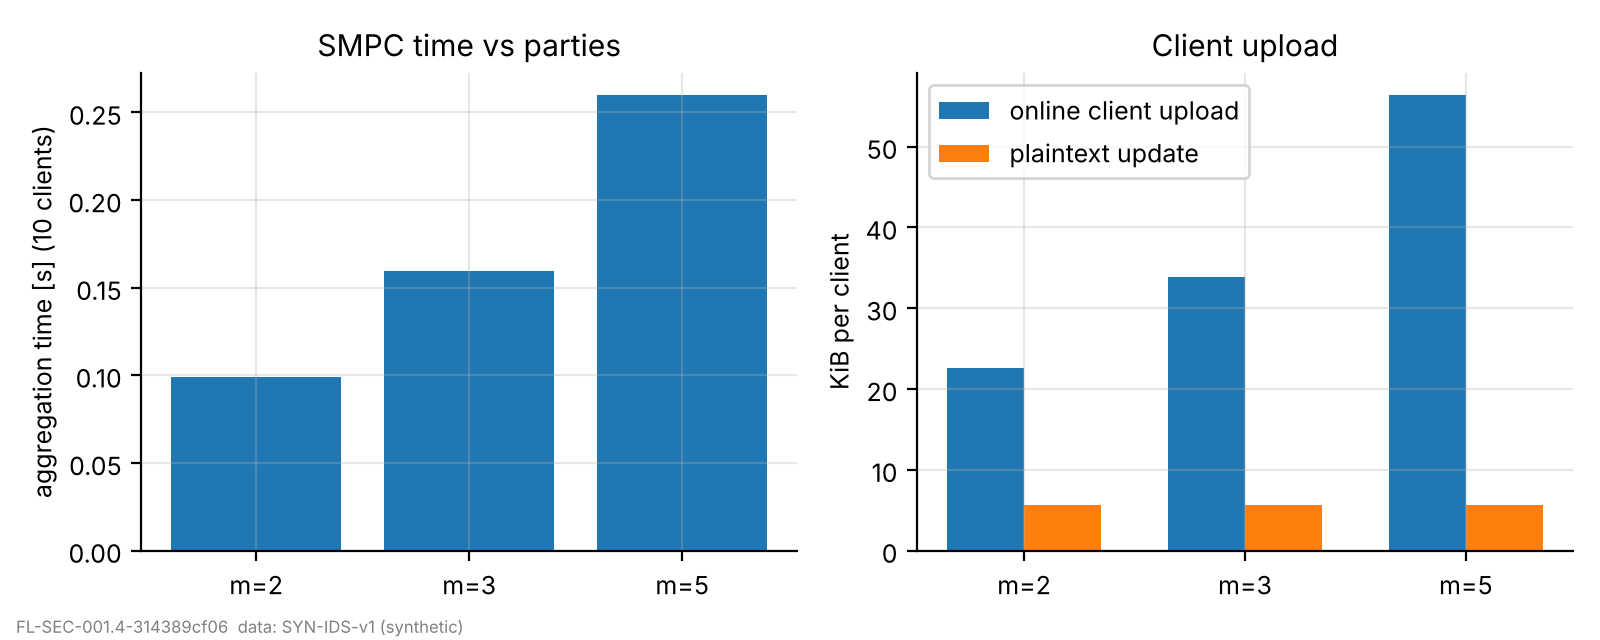

In [10]:
show_fig('task_1_4_smpc.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

MAC checking detects tampering (abort); correctness holds to fixed-point precision.

In [11]:
J = json.load(open(RES / 'task_1_4_smpc.json')); print({k: J[k] for k in J if k != 'provenance'} if isinstance(J, dict) else J)

{'parties': [{'parties_m': 2, 'clients': 10, 'collusion_threshold_parties': 1, 'time_s': 0.09915495000001329, 'max_abs_err': 3.241063298090041e-07, 'online_up_kb_per_client': 22.53125, 'offline_dealer_kb_total': 788.59375, 'party_to_party_kb': 22.5625, 'plaintext_kb_per_client': 5.6328125, 'online_overhead_x': 4.0}, {'parties_m': 3, 'clients': 10, 'collusion_threshold_parties': 2, 'time_s': 0.1593585589999975, 'max_abs_err': 3.1038010012834905e-07, 'online_up_kb_per_client': 33.796875, 'offline_dealer_kb_total': 1126.5625, 'party_to_party_kb': 67.640625, 'plaintext_kb_per_client': 5.6328125, 'online_overhead_x': 6.0}, {'parties_m': 5, 'clients': 10, 'collusion_threshold_parties': 4, 'time_s': 0.25970982299998013, 'max_abs_err': 3.1327410620479723e-07, 'online_up_kb_per_client': 56.328125, 'offline_dealer_kb_total': 1802.5, 'party_to_party_kb': 225.390625, 'plaintext_kb_per_client': 5.6328125, 'online_overhead_x': 10.0}], 'scaling': [{'clients': 5, 'time_s': 0.06573164200000292}, {'clie

## 16. Limitations
- MP-SPDZ binaries were unavailable → from-scratch implementation; not a production MPC.
- Trusted-dealer offline phase.
- Norm-bound check reveals norms to the parties.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Authenticated SMPC aggregation works in simulation; cost is high relative to SecAgg.

**Jira acceptance:** see `docs/fl_sec_001/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`damgard2012`, `beaver1991`, `shamir1979` — details in `docs/fl_sec_001/references.md`.